# DATA 255 - Lab 2: Super Resolution / Image Restoration
### Spring 2026 | San Jose State University
---
**Task:** Restore degraded LR images to clean HR images

**Input/Output:** Both 256x256x3

**Architecture:** Lightweight ResUNet (~4M params) — NPU friendly

**Professor Tips Applied:**
- Residual learning (learn LR to HR difference)
- L1 loss only (sharper outputs, better PSNR)
- Save checkpoints every 10 epochs
- Test ONNX export early
- Diverse calibration data
- Unique architecture

## Cell 1: Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted!')

Mounted at /content/drive
Drive mounted!


## Cell 2: Check GPU + Set Seeds

In [2]:
import torch
import numpy as np
import random
import os

# Set seeds for reproducibility
SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

print(f'PyTorch version : {torch.__version__}')
print(f'GPU available   : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU name        : {torch.cuda.get_device_name(0)}')
    print(f'GPU memory      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device    : {DEVICE}')
print(f'Seed            : {SEED}')

PyTorch version : 2.10.0+cu128
GPU available   : True
GPU name        : NVIDIA L4
GPU memory      : 23.7 GB
Using device    : cuda
Seed            : 42


## Cell 3: Unzip ALL 12 Dataset Files

In [3]:
import zipfile
import os
import time

DRIVE_PATH = '/content/drive/MyDrive/DL Lab2'
DATA_ROOT  = '/content/data'
os.makedirs(DATA_ROOT, exist_ok=True)

zip_files = {
    'LR_train' : f'{DRIVE_PATH}/LR_train.zip',
    'LR_train1': f'{DRIVE_PATH}/LR_train1.zip',
    'LR_train2': f'{DRIVE_PATH}/LR_train2.zip',
    'LR_train3': f'{DRIVE_PATH}/LR_train3.zip',
    'LR_train4': f'{DRIVE_PATH}/LR_train4.zip',
    'HR_train' : f'{DRIVE_PATH}/HR_train.zip',
    'HR_train1': f'{DRIVE_PATH}/HR_train1.zip',
    'HR_train2': f'{DRIVE_PATH}/HR_train2.zip',
    'HR_train3': f'{DRIVE_PATH}/HR_train3.zip',
    'HR_train4': f'{DRIVE_PATH}/HR_train4.zip',
    'LR_val'   : f'{DRIVE_PATH}/LR_val.zip',
    'HR_val'   : f'{DRIVE_PATH}/HR_val.zip',
}

for name, zip_path in zip_files.items():
    extract_path = os.path.join(DATA_ROOT, name)
    if os.path.exists(extract_path):
        print(f'Already extracted: {name} ')
        continue
    for attempt in range(3):
        try:
            print(f'Extracting {name}... (attempt {attempt+1})')
            with zipfile.ZipFile(zip_path, 'r') as zf:
                zf.extractall(extract_path)
            print(f'  Done -> {extract_path} ')
            break
        except OSError as e:
            print(f'  Error: {e} - Remounting Drive...')
            time.sleep(3)
            from google.colab import drive
            drive.mount('/content/drive', force_remount=True)
            time.sleep(5)

print('\nAll zips extracted!')

Extracting LR_train... (attempt 1)
  Done -> /content/data/LR_train 
Extracting LR_train1... (attempt 1)
  Done -> /content/data/LR_train1 
Extracting LR_train2... (attempt 1)
  Done -> /content/data/LR_train2 
Extracting LR_train3... (attempt 1)
  Done -> /content/data/LR_train3 
Extracting LR_train4... (attempt 1)
  Done -> /content/data/LR_train4 
Extracting HR_train... (attempt 1)
  Done -> /content/data/HR_train 
Extracting HR_train1... (attempt 1)
  Done -> /content/data/HR_train1 
Extracting HR_train2... (attempt 1)
  Done -> /content/data/HR_train2 
Extracting HR_train3... (attempt 1)
  Done -> /content/data/HR_train3 
Extracting HR_train4... (attempt 1)
  Done -> /content/data/HR_train4 
Extracting LR_val... (attempt 1)
  Done -> /content/data/LR_val 
Extracting HR_val... (attempt 1)
  Done -> /content/data/HR_val 

All zips extracted!


## Cell 4: Verify Dataset

In [4]:
from glob import glob

def get_images(folder):
    return sorted([
        f for f in glob(os.path.join(folder, '**', '*'), recursive=True)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ])

lr_train_dirs = [
    f'{DATA_ROOT}/LR_train',  f'{DATA_ROOT}/LR_train1',
    f'{DATA_ROOT}/LR_train2', f'{DATA_ROOT}/LR_train3',
    f'{DATA_ROOT}/LR_train4'
]
hr_train_dirs = [
    f'{DATA_ROOT}/HR_train',  f'{DATA_ROOT}/HR_train1',
    f'{DATA_ROOT}/HR_train2', f'{DATA_ROOT}/HR_train3',
    f'{DATA_ROOT}/HR_train4'
]

total_lr = sum(len(get_images(d)) for d in lr_train_dirs)
total_hr = sum(len(get_images(d)) for d in hr_train_dirs)

print(f'LR Train images  : {total_lr}')
print(f'HR Train images  : {total_hr}')
print(f'LR Val images    : {len(get_images(f"{DATA_ROOT}/LR_val"))}')
print(f'HR Val images    : {len(get_images(f"{DATA_ROOT}/HR_val"))}')
assert total_lr == total_hr, 'LR/HR mismatch!'
print(f'\nTotal train pairs: {total_lr} ')

LR Train images  : 3325
HR Train images  : 3325
LR Val images    : 100
HR Val images    : 100

Total train pairs: 3325 


## Cell 5: Imports

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
from PIL import Image
import numpy as np
import os
import random
import math
import matplotlib.pyplot as plt
from glob import glob

print('All imports successful!')

All imports successful!


## Cell 6: Dataset Class

In [6]:
class SRDataset(Dataset):
    """
    Image Restoration Dataset.
    Loads paired LR (degraded) and HR (clean) images.
    Both 256x256x3.
    Normalization: [0,1] matches NPU preprocessing.
    """
    def __init__(self, lr_dir, hr_dir, augment=False):
        self.augment  = augment
        self.lr_files = sorted([
            f for f in glob(os.path.join(lr_dir, '**', '*'), recursive=True)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])
        self.hr_files = sorted([
            f for f in glob(os.path.join(hr_dir, '**', '*'), recursive=True)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])
        assert len(self.lr_files) == len(self.hr_files), \
            f'Mismatch: {len(self.lr_files)} LR vs {len(self.hr_files)} HR'

        # Normalize to [0,1] matches NPU step_2/step_3 scripts
        self.transform = transforms.Compose([
            transforms.Resize((256, 256), Image.BILINEAR),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.lr_files)

    def __getitem__(self, idx):
        lr_img = Image.open(self.lr_files[idx]).convert('RGB')
        hr_img = Image.open(self.hr_files[idx]).convert('RGB')

        if self.augment:
            if random.random() > 0.5:
                lr_img = TF.hflip(lr_img)
                hr_img = TF.hflip(hr_img)
            if random.random() > 0.5:
                lr_img = TF.vflip(lr_img)
                hr_img = TF.vflip(hr_img)
            if random.random() > 0.5:
                angle  = random.choice([90, 180, 270])
                lr_img = TF.rotate(lr_img, angle)
                hr_img = TF.rotate(hr_img, angle)
            if random.random() > 0.5:
                factor = random.uniform(0.8, 1.2)
                lr_img = TF.adjust_brightness(lr_img, factor)
                hr_img = TF.adjust_brightness(hr_img, factor)
            if random.random() > 0.5:
                factor = random.uniform(0.8, 1.2)
                lr_img = TF.adjust_contrast(lr_img, factor)
                hr_img = TF.adjust_contrast(hr_img, factor)

        return self.transform(lr_img), self.transform(hr_img)

print('SRDataset ready!')

SRDataset ready!


## Cell 7: Load ALL Training Data

In [7]:
train_datasets = []

for lr_dir, hr_dir in zip(lr_train_dirs, hr_train_dirs):
    ds = SRDataset(lr_dir, hr_dir, augment=True)
    train_datasets.append(ds)
    print(f'Loaded: {os.path.basename(lr_dir)} -> {len(ds)} pairs')

full_train_dataset = ConcatDataset(train_datasets)

val_dataset = SRDataset(
    f'{DATA_ROOT}/LR_val',
    f'{DATA_ROOT}/HR_val',
    augment=False
)

print(f'\nTotal training pairs : {len(full_train_dataset)}')
print(f'Total val pairs      : {len(val_dataset)}')

Loaded: LR_train -> 289 pairs
Loaded: LR_train1 -> 663 pairs
Loaded: LR_train2 -> 782 pairs
Loaded: LR_train3 -> 810 pairs
Loaded: LR_train4 -> 781 pairs

Total training pairs : 3325
Total val pairs      : 100


## Cell 8: Hyperparameters & DataLoaders

In [14]:
BATCH_SIZE    = 16
LEARNING_RATE = 2e-4
NUM_EPOCHS    = 300
NUM_WORKERS   = 2
SAVE_EVERY    = 10

SAVE_DIR = '/content/drive/MyDrive/DL Lab2/outputs'
os.makedirs(SAVE_DIR, exist_ok=True)

train_loader = DataLoader(
    full_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f'Train batches : {len(train_loader)}')
print(f'Val batches   : {len(val_loader)}')
print(f'Batch size    : {BATCH_SIZE}')
print(f'Epochs        : {NUM_EPOCHS}')
print(f'Learning rate : {LEARNING_RATE}')

Train batches : 208
Val batches   : 7
Batch size    : 16
Epochs        : 300
Learning rate : 0.0002


## Cell 9: Lightweight ResUNet Model (~4M params)
> NPU friendly — similar size to classmates
> Unique: ResBlocks + Dilated bottleneck + Channel Attention + Residual learning

In [4]:
# ── Channel Attention ─────────────────────────────────────────────────────────
class ChannelAttention(nn.Module):
    """
    Recalibrates channel responses.
    Helps model focus on artifact-relevant features.
    """
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, max(channels // reduction, 4), bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(max(channels // reduction, 4), channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y


# ── Residual Block ────────────────────────────────────────────────────────────
class ResBlock(nn.Module):
    """
    Lightweight residual block with channel attention.
    """
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels)
        )
        self.ca   = ChannelAttention(channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        out = self.block(x)
        out = self.ca(out)
        return self.relu(out + x)


# ── Dilated Bottleneck ────────────────────────────────────────────────────────
class DilatedBottleneck(nn.Module):
    """
    Multi-scale dilated convolutions in bottleneck.
    Captures artifact patterns at 4 scales simultaneously.
    """
    def __init__(self, channels):
        super().__init__()
        mid = channels // 4
        self.d1 = nn.Conv2d(channels, mid, 3, padding=1,  dilation=1, bias=False)
        self.d2 = nn.Conv2d(channels, mid, 3, padding=2,  dilation=2, bias=False)
        self.d4 = nn.Conv2d(channels, mid, 3, padding=4,  dilation=4, bias=False)
        self.d8 = nn.Conv2d(channels, mid, 3, padding=8,  dilation=8, bias=False)
        self.fuse = nn.Sequential(
            nn.Conv2d(mid * 4, channels, 1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        out = torch.cat([
            torch.relu(self.d1(x)),
            torch.relu(self.d2(x)),
            torch.relu(self.d4(x)),
            torch.relu(self.d8(x))
        ], dim=1)
        return self.fuse(out) + x


# ── Encoder Block ─────────────────────────────────────────────────────────────
class EncoderBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
        self.res  = ResBlock(out_ch)
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        x    = self.conv(x)
        skip = self.res(x)
        down = self.pool(skip)
        return skip, down


# ── Decoder Block ─────────────────────────────────────────────────────────────
class DecoderBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2, bias=False)
        self.conv = nn.Sequential(
            nn.Conv2d(out_ch + skip_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
        self.res = ResBlock(out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([x, skip], dim=1)
        x = self.conv(x)
        return self.res(x)


# ── Main Model: LightResUNet (~4M params) ─────────────────────────────────────
class LightResUNet(nn.Module):
    """
    Lightweight Residual U-Net for Image Restoration.
    Input : [B, 3, 256, 256] degraded LR image
    Output: [B, 3, 256, 256] restored HR image

    Key features:
    - ~4M parameters (NPU friendly)
    - Residual learning: predicts LR->HR difference
    - U-Net skip connections
    - Dilated bottleneck for multi-scale artifact capture
    - Channel attention in ResBlocks
    """
    def __init__(self, base_ch=16):
        super().__init__()

        # Encoder
        self.enc1 = EncoderBlock(3,         base_ch)    # 256->128
        self.enc2 = EncoderBlock(base_ch,   base_ch*2)  # 128->64
        self.enc3 = EncoderBlock(base_ch*2, base_ch*4)  # 64->32
        self.enc4 = EncoderBlock(base_ch*4, base_ch*8)  # 32->16

        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(base_ch*8, base_ch*16, 3, padding=1, bias=False),
            nn.BatchNorm2d(base_ch*16),
            nn.ReLU(inplace=True),
            DilatedBottleneck(base_ch*16),
            ResBlock(base_ch*16),
            nn.Conv2d(base_ch*16, base_ch*8, 3, padding=1, bias=False),
            nn.BatchNorm2d(base_ch*8),
            nn.ReLU(inplace=True)
        )

        # Decoder
        self.dec4 = DecoderBlock(base_ch*8, base_ch*8, base_ch*4)
        self.dec3 = DecoderBlock(base_ch*4, base_ch*4, base_ch*2)
        self.dec2 = DecoderBlock(base_ch*2, base_ch*2, base_ch)
        self.dec1 = DecoderBlock(base_ch,   base_ch,   base_ch)

        # Output: predict residual
        self.out_conv = nn.Sequential(
            nn.Conv2d(base_ch, base_ch, 3, padding=1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(base_ch, 3, 1)
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        lr_input = x  # save for residual

        # Encoder
        s1, x = self.enc1(x)
        s2, x = self.enc2(x)
        s3, x = self.enc3(x)
        s4, x = self.enc4(x)

        # Bottleneck
        x = self.bottleneck(x)

        # Decoder
        x = self.dec4(x, s4)
        x = self.dec3(x, s3)
        x = self.dec2(x, s2)
        x = self.dec1(x, s1)

        # Residual learning (professor tip 3)
        # Predict difference, add to LR input
        residual = self.out_conv(x)
        return torch.clamp(lr_input + residual, 0, 1)


# Build model with base_ch=16 (~4M params, NPU friendly)
model = LightResUNet(base_ch=16).to(DEVICE)

# Test shape
dummy = torch.randn(1, 3, 256, 256).to(DEVICE)
with torch.no_grad():
    out = model(dummy)

print(f'Input  shape     : {dummy.shape}')
print(f'Output shape     : {out.shape}')

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params     : {total:,}')
print(f'Trainable params : {trainable:,}')
print(f'NPU friendly     : {"Yes" if total < 10_000_000 else "⚠️ Check"}')

Input  shape     : torch.Size([1, 3, 256, 256])
Output shape     : torch.Size([1, 3, 256, 256])
Total params     : 3,239,171
Trainable params : 3,239,171
NPU friendly     : Yes


## Cell 10: Test ONNX Export Early
> Professor Tip 1: Always test ONNX before training!

In [10]:
TEST_ONNX = os.path.join(SAVE_DIR, 'test_export.onnx')
model.eval()
dummy_input = torch.randn(1, 3, 256, 256).to(DEVICE)

try:
    torch.onnx.export(
        model,
        dummy_input,
        TEST_ONNX,
        export_params=True,
        opset_version=11,
        do_constant_folding=True,
        input_names=['image'],
        output_names=['predictions'],
        dynamic_axes={
            'image'      : {0: 'batch_size'},
            'predictions': {0: 'batch_size'}
        },
        verbose=False
    )
    print(f'ONNX test export successful! ')
    print(f'Size: {os.path.getsize(TEST_ONNX)/1e6:.1f} MB')
    print(f'Safe to train!')
except Exception as e:
    print(f'ONNX export FAILED: {e}')
    print('Fix model before training!')

ONNX export FAILED: No module named 'onnxscript'
Fix model before training!


## Cell 11: Loss Function & PSNR
> Professor Tip 4: L1 loss only — avoids blurry outputs

In [5]:
# L1 loss only (professor tip 4)
# MSE produces blurry outputs which hurts PSNR
criterion = nn.L1Loss()

def compute_psnr(pred, target):
    """
    Compute PSNR in dB.
    Images in [0,1] range.
    Higher = better. Target > 30 dB.
    """
    mse = torch.mean((pred.clamp(0,1) - target.clamp(0,1)) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * math.log10(1.0 / math.sqrt(mse.item()))

print('Loss : L1 only (professor tip 4)')
print('PSNR : computed on [0,1] range')

Loss : L1 only (professor tip 4)
PSNR : computed on [0,1] range


## Cell 12: Optimizer & Scheduler

In [12]:
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999),
    weight_decay=1e-5
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

print('Optimizer : Adam (lr=2e-4)')
print('Scheduler : ReduceLROnPlateau (maximize PSNR)')

Optimizer : Adam (lr=2e-4)
Scheduler : ReduceLROnPlateau (maximize PSNR)


## Cell 13: Training Loop

In [15]:
train_losses = []
val_psnrs    = []
best_psnr    = 0.0

print('=' * 65)
print('Starting Training — LightResUNet on ALL 12 zips')
print('L1 Loss + Residual Learning + Checkpoints every 10 epochs')
print('=' * 65)

for epoch in range(1, NUM_EPOCHS + 1):

    model.train()
    epoch_loss = 0.0

    for lr_imgs, hr_imgs in train_loader:
        lr_imgs = lr_imgs.to(DEVICE)
        hr_imgs = hr_imgs.to(DEVICE)

        optimizer.zero_grad()             # clear gradients
        pred = model(lr_imgs)             # forward: LR + residual
        loss = criterion(pred, hr_imgs)   # L1 loss
        loss.backward()                   # compute gradients

        # Gradient clipping for stable training
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()                  # update weights
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation
    model.eval()
    total_psnr = 0.0

    with torch.no_grad():
        for lr_imgs, hr_imgs in val_loader:
            lr_imgs = lr_imgs.to(DEVICE)
            hr_imgs = hr_imgs.to(DEVICE)
            pred    = model(lr_imgs)
            for i in range(pred.shape[0]):
                total_psnr += compute_psnr(pred[i], hr_imgs[i])

    avg_psnr   = total_psnr / len(val_dataset)
    val_psnrs.append(avg_psnr)
    scheduler.step(avg_psnr)
    current_lr = optimizer.param_groups[0]['lr']

    print(f'Epoch [{epoch:03d}/{NUM_EPOCHS}] | '
          f'Loss: {avg_train_loss:.4f} | '
          f'Val PSNR: {avg_psnr:.2f} dB | '
          f'LR: {current_lr:.2e}')

    # ── Save best model ────────────────────────────────────────────────────────
    if avg_psnr > best_psnr:
        best_psnr = avg_psnr
        torch.save({
            'epoch'               : epoch,
            'model_state_dict'    : model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_psnr'           : best_psnr,
            'architecture'        : 'LightResUNet',
            'base_ch'             : 16
        }, os.path.join(SAVE_DIR, 'best_model.pth'))
        print(f'  --> New best! PSNR: {best_psnr:.2f} dB saved!')

    # ── Checkpoint every 10 epochs (professor tip 2) ───────────────────────────
    if epoch % SAVE_EVERY == 0:
        torch.save({
            'epoch'           : epoch,
            'model_state_dict': model.state_dict(),
            'psnr'            : avg_psnr,
            'architecture'    : 'LightResUNet',
            'base_ch'         : 16
        }, os.path.join(SAVE_DIR, f'checkpoint_epoch_{epoch}.pth'))
        print(f'  --> Checkpoint saved at epoch {epoch}')

print('=' * 65)
print(f'Training complete! Best PSNR: {best_psnr:.2f} dB')
print('=' * 65)

Starting Training — LightResUNet on ALL 12 zips
L1 Loss + Residual Learning + Checkpoints every 10 epochs
Epoch [001/300] | Loss: 0.0384 | Val PSNR: 21.64 dB | LR: 2.00e-04
  --> New best! PSNR: 21.64 dB saved!
Epoch [002/300] | Loss: 0.0384 | Val PSNR: 21.62 dB | LR: 2.00e-04
Epoch [003/300] | Loss: 0.0385 | Val PSNR: 21.64 dB | LR: 2.00e-04
  --> New best! PSNR: 21.64 dB saved!
Epoch [004/300] | Loss: 0.0386 | Val PSNR: 21.64 dB | LR: 2.00e-04
Epoch [005/300] | Loss: 0.0384 | Val PSNR: 21.65 dB | LR: 2.00e-04
  --> New best! PSNR: 21.65 dB saved!
Epoch [006/300] | Loss: 0.0384 | Val PSNR: 21.65 dB | LR: 2.00e-04
  --> New best! PSNR: 21.65 dB saved!
Epoch [007/300] | Loss: 0.0384 | Val PSNR: 21.65 dB | LR: 2.00e-04
  --> New best! PSNR: 21.65 dB saved!
Epoch [008/300] | Loss: 0.0384 | Val PSNR: 21.66 dB | LR: 2.00e-04
  --> New best! PSNR: 21.66 dB saved!
Epoch [009/300] | Loss: 0.0383 | Val PSNR: 21.66 dB | LR: 2.00e-04
Epoch [010/300] | Loss: 0.0386 | Val PSNR: 21.57 dB | LR: 2.00e

## Cell 14: Plot Training Curves

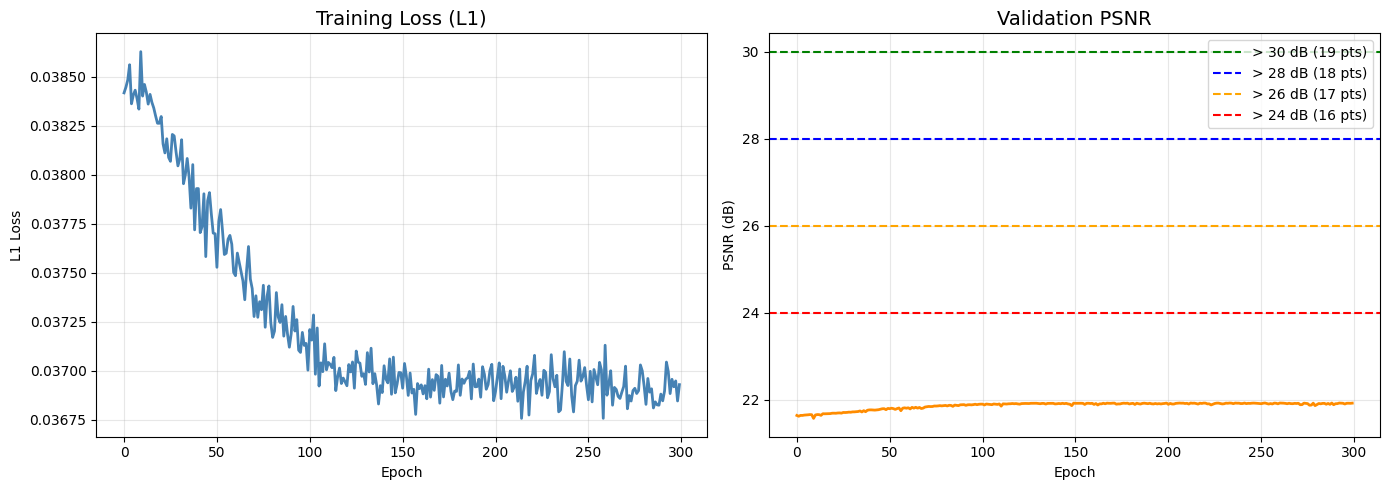

Saved to Drive!


In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, color='steelblue', linewidth=2)
ax1.set_title('Training Loss (L1)', fontsize=14)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('L1 Loss')
ax1.grid(True, alpha=0.3)

ax2.plot(val_psnrs, color='darkorange', linewidth=2)
ax2.axhline(y=30, color='green',  linestyle='--', label='> 30 dB (19 pts)')
ax2.axhline(y=28, color='blue',   linestyle='--', label='> 28 dB (18 pts)')
ax2.axhline(y=26, color='orange', linestyle='--', label='> 26 dB (17 pts)')
ax2.axhline(y=24, color='red',    linestyle='--', label='> 24 dB (16 pts)')
ax2.set_title('Validation PSNR', fontsize=14)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('PSNR (dB)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150)
plt.show()
print('Saved to Drive!')

## Cell 15: Visualize Predictions

Best model: Epoch 253 | PSNR: 21.93 dB


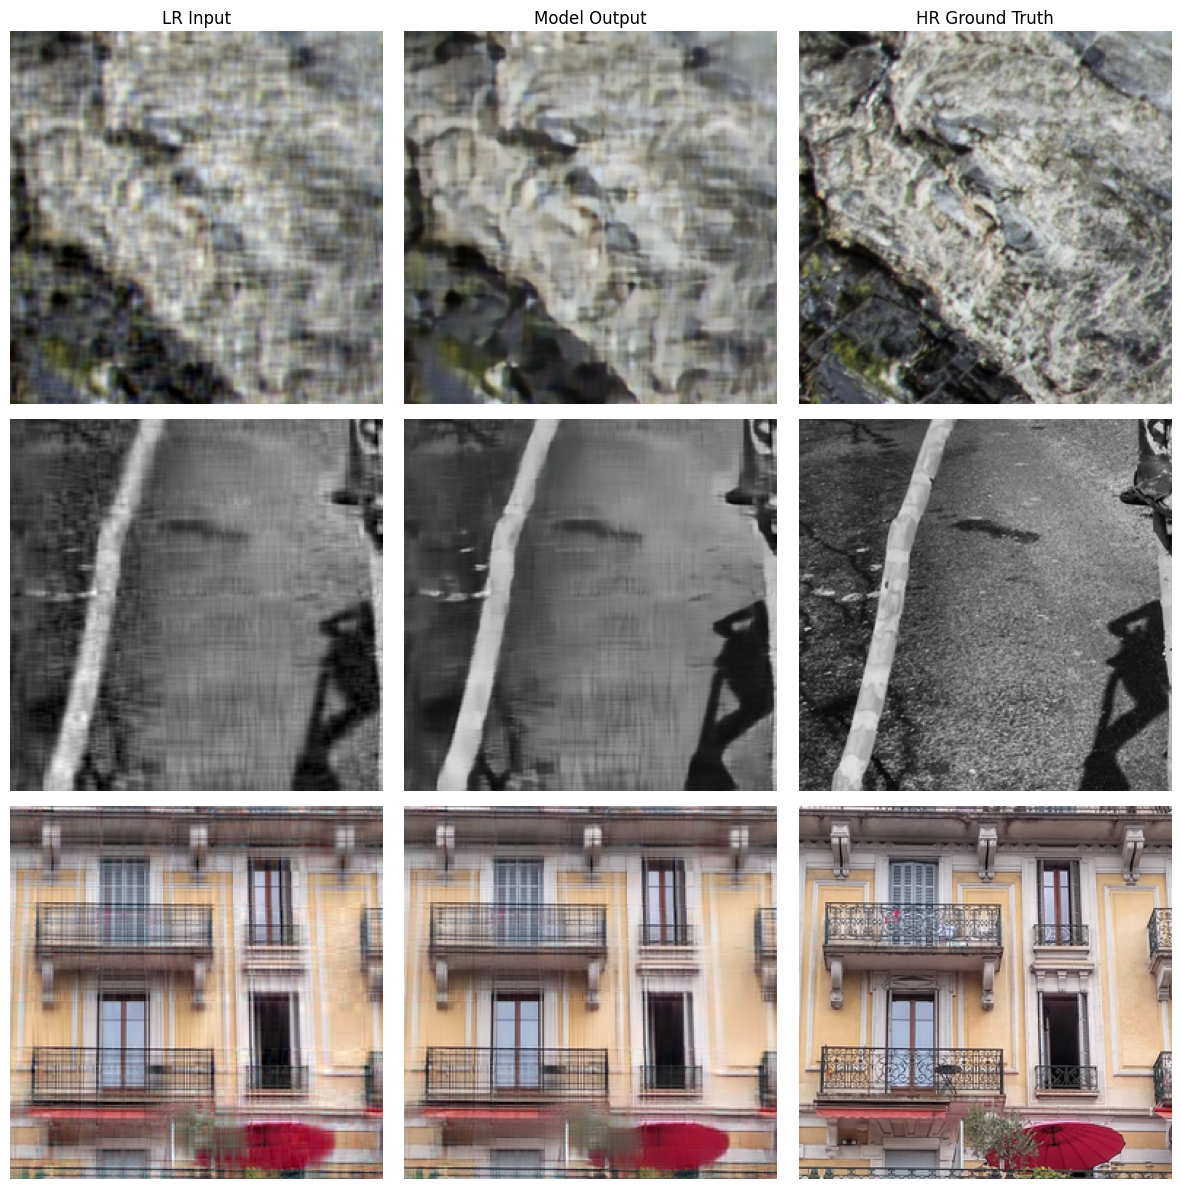

Predictions saved!


In [17]:
checkpoint = torch.load(
    os.path.join(SAVE_DIR, 'best_model.pth'),
    map_location=DEVICE
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'Best model: Epoch {checkpoint["epoch"]} | PSNR: {checkpoint["best_psnr"]:.2f} dB')

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes[0,0].set_title('LR Input',        fontsize=12)
axes[0,1].set_title('Model Output',    fontsize=12)
axes[0,2].set_title('HR Ground Truth', fontsize=12)

lr_batch, hr_batch = next(iter(val_loader))
lr_batch = lr_batch.to(DEVICE)
hr_batch = hr_batch.to(DEVICE)

with torch.no_grad():
    pred_batch = model(lr_batch)

for i in range(3):
    lr_np   = lr_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    pred_np = pred_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    hr_np   = hr_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    psnr_v  = compute_psnr(pred_batch[i], hr_batch[i])

    axes[i,0].imshow(lr_np);   axes[i,0].axis('off')
    axes[i,1].imshow(pred_np); axes[i,1].set_xlabel(f'PSNR: {psnr_v:.2f} dB'); axes[i,1].axis('off')
    axes[i,2].imshow(hr_np);   axes[i,2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'sample_predictions.png'), dpi=150)
plt.show()
print('Predictions saved!')

## Cell 16: Save Calibration Images
> Professor Tip 5: Diverse calibration data from all 5 zips

In [18]:
CALIB_DIR = os.path.join(SAVE_DIR, 'calibration_images')
os.makedirs(CALIB_DIR, exist_ok=True)

NUM_CALIB_PER_ZIP = 10  # 10 from each zip = 50 total
calib_count = 0

for lr_dir in lr_train_dirs:
    files = sorted([
        f for f in glob(os.path.join(lr_dir, '**', '*'), recursive=True)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ])
    step     = max(1, len(files) // NUM_CALIB_PER_ZIP)
    selected = files[::step][:NUM_CALIB_PER_ZIP]

    for f in selected:
        img = Image.open(f).convert('RGB')
        img = img.resize((256, 256), Image.BILINEAR)
        img.save(os.path.join(CALIB_DIR, f'calib_{calib_count:03d}.jpg'))
        calib_count += 1

print(f'Saved {calib_count} diverse calibration images')
print(f'From all 5 LR training zips')
print(f'Location: {CALIB_DIR}')

Saved 50 diverse calibration images
From all 5 LR training zips
Location: /content/drive/MyDrive/DL Lab2/outputs/calibration_images


## Cell 17: Export Final ONNX
> Based on step_1_model_saving.py reference

In [6]:
# Install missing dependency
!pip install onnxscript -q
print('onnxscript installed!')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 119.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.1/164.1 kB 19.5 MB/s eta 0:00:00
onnxscript installed!


In [9]:
import torch
import onnx
import os
import shutil

# ── Define paths manually (since Cell 8 was skipped) ─────────────────────────
SAVE_DIR   = '/content/drive/MyDrive/DL Lab2/outputs'
LOCAL_ONNX = '/content/sr_model.onnx'

# ── Load best model ───────────────────────────────────────────────────────────
checkpoint = torch.load(
    os.path.join(SAVE_DIR, 'best_model.pth'),
    map_location=DEVICE
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'Loaded: Epoch {checkpoint["epoch"]} | PSNR: {checkpoint["best_psnr"]:.2f} dB')

# ── Export ONNX to local first ────────────────────────────────────────────────
dummy_input = torch.randn(1, 3, 256, 256).to(DEVICE)

torch.onnx.export(
    model,
    dummy_input,
    LOCAL_ONNX,
    export_params=True,
    opset_version=11,
    do_constant_folding=True,
    input_names=['image'],
    output_names=['predictions'],
    dynamic_axes={
        'image'      : {0: 'batch_size'},
        'predictions': {0: 'batch_size'}
    },
    verbose=False
)

# ── Merge into single file ────────────────────────────────────────────────────
onnx_model = onnx.load(LOCAL_ONNX)
onnx.save_model(
    onnx_model,
    LOCAL_ONNX,
    save_as_external_data=False
)

# ── Verify ────────────────────────────────────────────────────────────────────
onnx.checker.check_model(onnx.load(LOCAL_ONNX))
size_mb = os.path.getsize(LOCAL_ONNX) / 1e6
print(f'ONNX size  : {size_mb:.1f} MB')
print(f'Single file: {"Yes" if size_mb > 1 else "Still split"}')

# ── Copy to Drive ─────────────────────────────────────────────────────────────
DRIVE_ONNX = os.path.join(SAVE_DIR, 'sr_model.onnx')
shutil.copy2(LOCAL_ONNX, DRIVE_ONNX)
print(f'Saved to Drive ')


Loaded: Epoch 253 | PSNR: 21.93 dB


/tmp/ipykernel_3140/2444802478.py:22: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W0404 07:07:00.460000 3140 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 11 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0404 07:07:01.236000 3140 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, a

Applied 82 of general pattern rewrite rules.
ONNX size  : 13.2 MB
Single file: Yes
Saved to Drive 


## Cell 18: Verify ONNX

In [22]:
import onnx

onnx_model = onnx.load(ONNX_PATH)
onnx.checker.check_model(onnx_model)
print('ONNX model is valid! ')

print('\nInputs:')
for inp in onnx_model.graph.input:
    print(f'  {inp.name}: {[d.dim_value for d in inp.type.tensor_type.shape.dim]}')

print('\nOutputs:')
for out in onnx_model.graph.output:
    print(f'  {out.name}: {[d.dim_value for d in out.type.tensor_type.shape.dim]}')

print(f'\nReady for NPU compilation! ')

ONNX model is valid! 

Inputs:
  image: [0, 3, 256, 256]

Outputs:
  predictions: [0, 3, 256, 256]

Ready for NPU compilation! 


## Cell 19: Final Summary

In [23]:
total_params = sum(p.numel() for p in model.parameters())

print('=' * 65)
print('LAB 2 — COMPLETE!')
print('=' * 65)
print(f'Architecture         : LightResUNet (base_ch=16)')
print(f'Total Parameters     : {total_params:,}')
print(f'Best Validation PSNR : {best_psnr:.2f} dB')
print(f'Best model (.pth)    : {SAVE_DIR}/best_model.pth')
print(f'ONNX model           : {ONNX_PATH}')
print(f'Calibration images   : {CALIB_DIR}')
print()
print('CANVAS SUBMISSION CHECKLIST:')
print('  training_script.py')
print('  onnx_to_mxq_script.py')
print('  sr_model.mxq')
print('  best_model.pth  (professor requested)')
print()
print('NEXT STEPS (NPU Lab):')
print('  1. Download sr_model.onnx from Drive')
print('  2. Download calibration_images/ from Drive')
print('  3. Run step_2 to compile .onnx -> .mxq')
print('  4. Run step_3 to get PSNR score on NPU')
print('  5. Submit on Canvas before March 29th!')
print('=' * 65)

LAB 2 — COMPLETE!
Architecture         : LightResUNet (base_ch=16)
Total Parameters     : 3,239,171
Best Validation PSNR : 21.93 dB
Best model (.pth)    : /content/drive/MyDrive/DL Lab2/outputs/best_model.pth
ONNX model           : /content/drive/MyDrive/DL Lab2/outputs/sr_model.onnx
Calibration images   : /content/drive/MyDrive/DL Lab2/outputs/calibration_images

CANVAS SUBMISSION CHECKLIST:
  training_script.py
  onnx_to_mxq_script.py
  sr_model.mxq
  best_model.pth  (professor requested)

NEXT STEPS (NPU Lab):
  1. Download sr_model.onnx from Drive
  2. Download calibration_images/ from Drive
  3. Run step_2 to compile .onnx -> .mxq
  4. Run step_3 to get PSNR score on NPU
  5. Submit on Canvas before March 29th!
